원본 데이터 크기: (1941, 34)
결측치: 0 / 중복 행: 0
병합 후 데이터 크기: (1941, 27)

[결함 유형 분포]


,count
Fault_Type,
Pastry,158
Z_Scratch,190
K_Scatch,391
Stains,72
Dirtiness,55
Bumps,402
Other_Faults,673



[이상치 현황]
탐지 기준: 사분위수 범위(IQR) 기준 - Q1 − 1.5×IQR 미만 또는 Q3 + 1.5×IQR 초과
대상 컬럼: 강종 이진 표시 2열과 Outside_Global_Index(고유값 3개)를 제외한 수치형 설명 변수 24개


,Q1,Q3,IQR,하한,상한,이상치 건수,이상치 비율(%)
Sum_of_Luminosity,9522.00,83011.00,73489.00,-100711.50,193244.50,399,20.56
Pixels_Areas,84.00,822.00,738.00,-1023.00,1929.00,395,20.35
Outside_X_Index,0.01,0.02,0.02,-0.02,0.05,370,19.06
X_Perimeter,15.00,84.00,69.00,-88.50,187.50,352,18.13
Steel_Plate_Thickness,40.00,80.00,40.00,-20.00,140.00,240,12.36
Y_Perimeter,13.00,83.00,70.00,-92.00,188.00,179,9.22
Maximum_of_Luminosity,124.00,140.00,16.00,100.00,164.00,146,7.52
Luminosity_Index,-0.20,-0.07,0.13,-0.39,0.13,134,6.90
Y_Maximum,471281.00,2183084.00,1711803.00,-2096423.50,4750788.50,81,4.17
Y_Minimum,471253.00,2183073.00,1711820.00,-2096477.00,4750803.00,81,4.17


이상치 건수 및 비율:
  - 상위: Sum_of_Luminosity 399건(20.56%), Pixels_Areas 395건(20.35%), Outside_X_Index 370건(19.06%), X_Perimeter 352건(18.13%), Steel_Plate_Thickness 240건(12.36%)
  - 적음: LogOfAreas 6건(0.31%), Log_Y_Index 4건(0.21%)
  - 이상치 없음: X_Minimum, X_Maximum, Square_Index, Length_of_Conveyer, Edges_Index, Edges_X_Index, Edges_Y_Index, Orientation_Index, SigmoidOfAreas
처리 방향: 이상치를 제거하거나 대체하지 않고 유지 (실제 결함의 크기·형태를 반영하는 값이며 원자료 오류 없음, 트리 계열 모델은 값의 순서로 분기)
종합 해석: Pixels_Areas 20.35% → LogOfAreas 0.31%로, 로그 변환 변수가 분포의 치우침을 완화한다. IQR 기준 이상치는 오류를 뜻하지 않으므로 특성을 보존한다.

[결함 유형 × 강종]


...

Pastry          2.2
Z_Scratch       0.5
K_Scatch        1.0
Stains          0.5
Dirtiness       1.9
Bumps           1.0
Other_Faults    1.0
Name: 클래스 배율, dtype: float64


최종 테스트 결과 - 앙상블(상위 2) + 확률 보정


,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1
0,0.8201,0.8527,0.8283,0.8527,0.8349


테스트 Macro F1 95% 신뢰구간: [0.786, 0.876]
  → 다른 코드와의 점수 차이가 이 구간 폭보다 작으면 우열을 단정하기 어렵다.

[Classification Report - Test]
              precision    recall  f1-score   support

      Pastry     0.5918    0.9062    0.7160        32
   Z_Scratch     1.0000    0.8947    0.9444        38
    K_Scatch     0.9744    0.9744    0.9744        78
      Stains     0.9286    0.9286    0.9286        14
   Dirtiness     0.7500    0.8182    0.7826        11
       Bumps     0.7568    0.6914    0.7226        81
Other_Faults     0.7969    0.7556    0.7757       135

    accuracy                         0.8201       389
   macro avg     0.8283    0.8527    0.8349       389
weighted avg     0.8305    0.8201    0.8217       389

[참고] 후보별 테스트 Macro F1


,Candidate,Test Macro F1 (보정 없음)
0,LightGBM,0.8305
1,Extra Trees,0.7988
2,CatBoost,0.8078
3,Random Forest,0.7850
4,앙상블(상위 2),0.8264
5,앙상블(상위 3),0.8220
6,앙상블(전체 4),0.8236


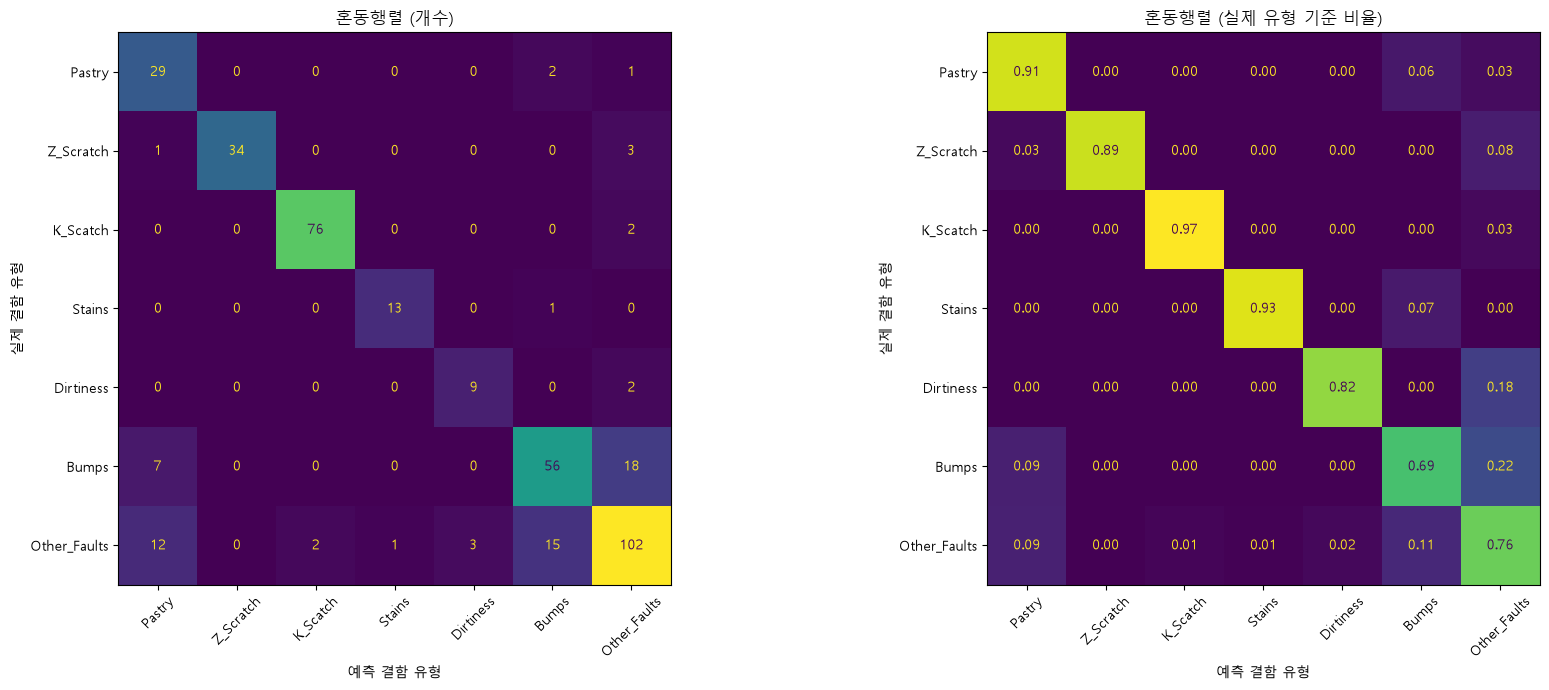


오분류: 70 / 389 (17.99%)


Count
Actual       Predicted          
Bumps        Other_Faults     18
Other_Faults Bumps            15
             Pastry           12
Bumps        Pastry            7
Z_Scratch    Other_Faults      3
Other_Faults Dirtiness         3
Dirtiness    Other_Faults      2
K_Scatch     Other_Faults      2
Pastry       Bumps             2
Other_Faults K_Scatch          2

,Feature,Importance Mean,Importance SD
0,Length_of_Conveyer,0.0947,0.0135
1,Steel_Type,0.0817,0.0135
2,Steel_Plate_Thickness,0.0733,0.0133
3,Y_Minimum,0.0370,0.0080
4,Orientation_Index,0.0171,0.0093
5,Maximum_of_Luminosity,0.0147,0.0060
6,Pixels_Areas,0.0129,0.0044
7,X_Minimum,0.0126,0.0101
8,Minimum_of_Luminosity,0.0120,0.0090
9,Edges_Y_Index,0.0118,0.0075


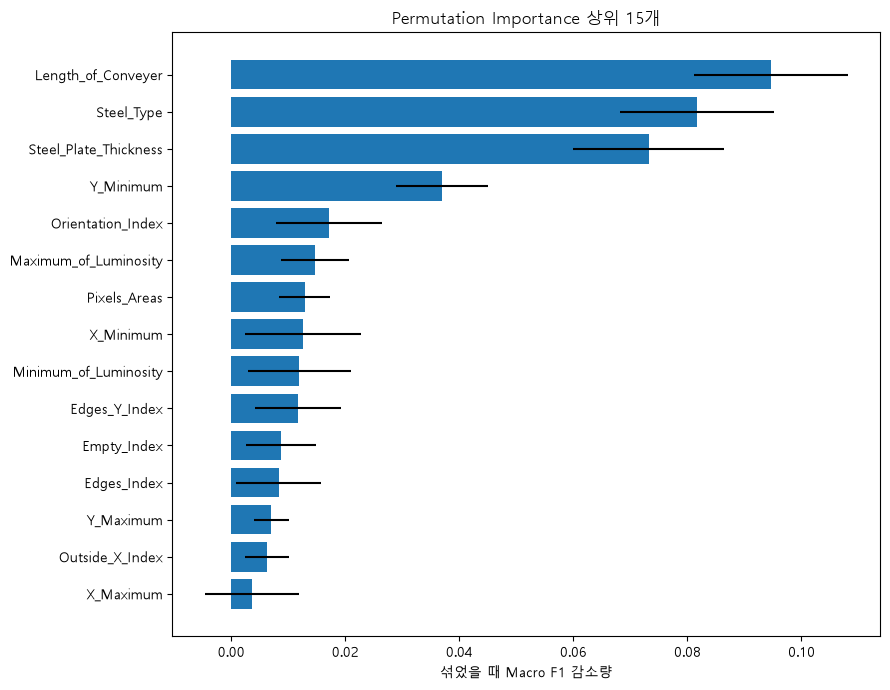


저장 완료: steel_fault_model_combined.joblib

[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]


,actual_fault,predicted_fault,confidence,prob_Pastry,prob_Z_Scratch,prob_K_Scatch,prob_Stains,prob_Dirtiness,prob_Bumps,prob_Other_Faults
904,Bumps,Bumps,0.979,0.008,0.000,0.000,0.0,0.0,0.979,0.013
492,K_Scatch,K_Scatch,1.000,0.000,0.000,1.000,0.0,0.0,0.000,0.000
232,Z_Scratch,Z_Scratch,0.982,0.000,0.982,0.000,0.0,0.0,0.003,0.015
1093,Bumps,Bumps,0.862,0.018,0.000,0.004,0.0,0.0,0.862,0.117
803,Stains,Stains,1.000,0.000,0.000,0.000,1.0,0.0,0.000,0.000


In [1]:
# ============================================================
# 0. 라이브러리 및 설정
# ============================================================

import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

from scipy.stats import chi2_contingency
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    RandomizedSearchCV,
    cross_val_score,
    cross_val_predict,
)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams["font.family"] = "Malgun Gothic"   # macOS: "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
DATA_PATH = "steel_plates_faults.csv"
N_ITER = 20            # 모델별 무작위 탐색 조합 수 (시간이 부족하면 줄이기)

STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
TARGET = "Fault_Type"

LABELS = list(range(len(FAULT_COLS)))
class_to_int = {name: i for i, name in enumerate(FAULT_COLS)}
int_to_class = {i: name for name, i in class_to_int.items()}
STEEL_CODE = {"A300": 0, "A400": 1}


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)


def score_row(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, labels=LABELS,
                                           average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, labels=LABELS,
                                     average="macro", zero_division=0),
        "Macro F1": macro_f1(y_true, y_pred),
    }


# ============================================================
# 1. 데이터 불러오기 및 열 병합 (원-핫 구조 검증 포함)
# ============================================================

raw_df = pd.read_csv(DATA_PATH)
print("원본 데이터 크기:", raw_df.shape)
print("결측치:", raw_df.isna().sum().sum(), "/ 중복 행:", raw_df.duplicated().sum())

for cols, label in [(STEEL_COLS, "강종"), (FAULT_COLS, "결함 유형")]:
    missing = [c for c in cols if c not in raw_df.columns]
    if missing:
        raise ValueError(f"{label} 열이 없습니다: {missing}")
    if not raw_df[cols].isin([0, 1]).all().all():
        raise ValueError(f"{label} 열은 0 또는 1이어야 합니다.")
    if not (raw_df[cols].sum(axis=1) == 1).all():
        raise ValueError(f"{label}이(가) 정확히 하나로 정해지지 않는 행이 있습니다.")


def merge_columns(data: pd.DataFrame) -> pd.DataFrame:
    """강종 2열 → Steel_Type, 결함 7열 → Fault_Type (결함 열이 없으면 강종만)"""
    out = data.copy()
    if set(STEEL_COLS).issubset(out.columns):
        pos = out.columns.get_loc("TypeOfSteel_A300")
        steel = np.where(out["TypeOfSteel_A300"] == 1, "A300", "A400")
        out = out.drop(columns=STEEL_COLS)
        out.insert(pos, "Steel_Type", steel)
    if set(FAULT_COLS).issubset(out.columns):
        out[TARGET] = out[FAULT_COLS].idxmax(axis=1)
        out = out.drop(columns=FAULT_COLS)
    return out


df = merge_columns(raw_df)
print("병합 후 데이터 크기:", df.shape)

print("\n[결함 유형 분포]")
display(df[TARGET].value_counts().reindex(FAULT_COLS).to_frame("count"))


# ============================================================
# 1-1. 이상치 확인 (IQR 기준)
# ============================================================
# 강종 이진 표시 2열과 세 값만 가지는 Outside_Global_Index를 제외한
# 수치형 설명 변수를 대상으로 Q1 − 1.5×IQR 미만 또는 Q3 + 1.5×IQR 초과를 이상치로 본다.
# 이상치는 제거·대체하지 않고 유지한다.
# ============================================================

OUTLIER_EXCLUDE = STEEL_COLS + ["Outside_Global_Index"] + FAULT_COLS
outlier_cols = [c for c in raw_df.select_dtypes(include="number").columns
                if c not in OUTLIER_EXCLUDE]

q1 = raw_df[outlier_cols].quantile(0.25)
q3 = raw_df[outlier_cols].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (raw_df[outlier_cols] < lower) | (raw_df[outlier_cols] > upper)

outlier_df = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr, "하한": lower, "상한": upper,
    "이상치 건수": is_outlier.sum(),
    "이상치 비율(%)": is_outlier.mean() * 100,
}).sort_values("이상치 건수", ascending=False)


def fmt(col):
    return f"{col} {outlier_df.loc[col, '이상치 건수']}건({outlier_df.loc[col, '이상치 비율(%)']:.2f}%)"


top5 = outlier_df.head(5).index.tolist()
no_outlier = outlier_df.index[outlier_df["이상치 건수"] == 0].tolist()

print("\n[이상치 현황]")
print("탐지 기준: 사분위수 범위(IQR) 기준 - Q1 − 1.5×IQR 미만 또는 Q3 + 1.5×IQR 초과")
print(f"대상 컬럼: 강종 이진 표시 2열과 Outside_Global_Index"
      f"(고유값 {raw_df['Outside_Global_Index'].nunique()}개)를 제외한 수치형 설명 변수 {len(outlier_cols)}개")
display(outlier_df.round(2))

print("이상치 건수 및 비율:")
print("  - 상위:", ", ".join(fmt(c) for c in top5))
print("  - 적음:", ", ".join(fmt(c) for c in ["LogOfAreas", "Log_Y_Index"]))
print("  - 이상치 없음:", ", ".join(no_outlier) if no_outlier else "없음")
print("처리 방향: 이상치를 제거하거나 대체하지 않고 유지 "
      "(실제 결함의 크기·형태를 반영하는 값이며 원자료 오류 없음, 트리 계열 모델은 값의 순서로 분기)")
print(f"종합 해석: Pixels_Areas {outlier_df.loc['Pixels_Areas', '이상치 비율(%)']:.2f}% → "
      f"LogOfAreas {outlier_df.loc['LogOfAreas', '이상치 비율(%)']:.2f}%로, "
      "로그 변환 변수가 분포의 치우침을 완화한다. IQR 기준 이상치는 오류를 뜻하지 않으므로 특성을 보존한다.")


# ============================================================
# 2. 강종 - 결함 유형 관계 (카이제곱 검정, Cramér's V)
# ============================================================

ct = pd.crosstab(df[TARGET], df["Steel_Type"]).reindex(FAULT_COLS)
chi2, p_value, dof, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))

print("\n[결함 유형 × 강종]")
display(ct)
print(f"Chi2 = {chi2:.1f}, df = {dof}, p = "
      f"{'<0.001' if p_value < 0.001 else round(p_value, 4)}, Cramér's V = {cramers_v:.3f}")


# ============================================================
# 3. 입력 변수 생성
# ============================================================
# Claude 코드의 파생변수 중 원본과 단조 관계라 트리 모델에 정보가 없는
# X_Range(≈Log_X_Index), Y_Range(≈Log_Y_Index), Mean_Luminosity(≈Luminosity_Index)는 제외.
# 정보가 새로 생기는 3개만 후보로 두고, 쓸지 말지는 4단계 교차검증으로 결정한다.
# ============================================================

EXTRA_FEATURES = ["Luminosity_Range", "Aspect_Ratio", "Perimeter_Area_Ratio"]


def build_features(data: pd.DataFrame, use_extra: bool) -> pd.DataFrame:
    out = data.drop(columns=[TARGET], errors="ignore").copy()
    out["Steel_Type"] = out["Steel_Type"].map(STEEL_CODE)
    if out["Steel_Type"].isna().any():
        raise ValueError("Steel_Type에 A300 / A400 이외의 값이 있습니다.")

    if use_extra:
        x_len = out["X_Maximum"] - out["X_Minimum"] + 1
        y_len = out["Y_Maximum"] - out["Y_Minimum"] + 1
        out["Luminosity_Range"] = out["Maximum_of_Luminosity"] - out["Minimum_of_Luminosity"]
        out["Aspect_Ratio"] = x_len / y_len
        out["Perimeter_Area_Ratio"] = (
            (out["X_Perimeter"] + out["Y_Perimeter"]) / out["Pixels_Areas"]
        )
    return out


y_all = df[TARGET].map(class_to_int).to_numpy()


# ============================================================
# 4. 개발 / 테스트 분할 (80 / 20, 층화)
# ============================================================

idx_dev, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)
y_dev, y_test = y_all[idx_dev], y_all[idx_test]
print(f"\n개발: {len(idx_dev)}개 / 테스트: {len(idx_test)}개")

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)


# ============================================================
# 5. 파생변수 사용 여부 결정 (개발 데이터 반복 교차검증)
# ============================================================

probe = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
feature_check = {}
for use_extra in [False, True]:
    X_tmp = build_features(df, use_extra).iloc[idx_dev]
    s = cross_val_score(probe, X_tmp, y_dev, cv=cv_rep, scoring="f1_macro", n_jobs=-1)
    feature_check["원본 + 파생 3개" if use_extra else "원본만"] = (s.mean(), s.std())
    print(f"{'원본 + 파생 3개' if use_extra else '원본만':<12} "
          f"CV Macro F1 = {s.mean():.4f} ± {s.std():.4f}")

# 평균이 표준편차의 절반 이상 좋아질 때만 파생변수 채택 (작은 차이는 단순한 쪽 선택)
gain = feature_check["원본 + 파생 3개"][0] - feature_check["원본만"][0]
USE_EXTRA = gain > 0.5 * feature_check["원본만"][1]
print("→ 파생변수 사용:", USE_EXTRA)

X_all = build_features(df, USE_EXTRA)
feature_cols = X_all.columns.tolist()
X_dev, X_test = X_all.iloc[idx_dev], X_all.iloc[idx_test]


# ============================================================
# 6. 모델 및 탐색 공간
# ============================================================
# GPT 코드의 기본 비교에서 선형/거리 기반 모델(로지스틱, SVM, KNN)은
# 트리 계열보다 Macro F1이 0.07~0.17 낮았으므로 트리 계열만 사용한다.
# class_weight는 모든 모델에서 튜닝 대상이다.
# ============================================================

models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "LightGBM": LGBMClassifier(objective="multiclass", random_state=RANDOM_STATE,
                               n_jobs=1, verbose=-1),
    "CatBoost": CatBoostClassifier(loss_function="MultiClass", random_seed=RANDOM_STATE,
                                   verbose=0, allow_writing_files=False, thread_count=1),
}

param_spaces = {
    "Random Forest": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "LightGBM": {
        "n_estimators": [200, 400, 700, 1000],
        "learning_rate": [0.02, 0.03, 0.05, 0.1],
        "num_leaves": [7, 15, 22, 31],
        "max_depth": [-1, 5, 7, 10],
        "min_child_samples": [5, 10, 20, 33],
        "subsample": [0.6, 0.8, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [0, 0.01, 1, 5],
        "class_weight": [None, "balanced"],
    },
    "CatBoost": {
        "iterations": [300, 500, 700],
        "depth": [4, 5, 6, 7],
        "learning_rate": [0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 7],
        "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
    },
}


# ============================================================
# 7. 하이퍼파라미터 튜닝 (개발 데이터 5-Fold, Macro F1)
# ============================================================

tuned = {}
tuning_rows = []

for name, model in models.items():
    print(f"\n{name} 튜닝 중... ({N_ITER}개 조합 × 5-Fold)")
    start = time.time()
    search = RandomizedSearchCV(
        model, param_spaces[name], n_iter=N_ITER, scoring="f1_macro",
        cv=cv5, random_state=RANDOM_STATE, n_jobs=-1, refit=False,
    )
    search.fit(X_dev, y_dev)
    tuned[name] = clone(model).set_params(**search.best_params_)

    tuning_rows.append({
        "Model": name,
        "CV Macro F1": search.best_score_,
        "CV SD": search.cv_results_["std_test_score"][search.best_index_],
        "Best Params": search.best_params_,
        "Time(s)": round(time.time() - start, 1),
    })
    print(f"  CV Macro F1 = {search.best_score_:.4f} | {search.best_params_}")

tuning_df = (pd.DataFrame(tuning_rows)
             .sort_values("CV Macro F1", ascending=False).reset_index(drop=True))
print("\n[튜닝 결과]")
display(tuning_df)


# ============================================================
# 8. Out-of-fold 확률 예측
# ============================================================
# 개발 데이터의 모든 행에 대해 "그 행을 학습에 쓰지 않은 모델"의 예측 확률을 얻는다.
# 앙상블 조합과 클래스별 확률 보정은 이 확률로만 결정하고 테스트는 건드리지 않는다.
# (튜닝에 쓴 fold와 같으므로 약간 낙관적일 수 있음 → 최종 판단은 테스트에서)
# ============================================================

oof = {}
for name, est in tuned.items():
    oof[name] = cross_val_predict(
        clone(est), X_dev, y_dev, cv=cv5, method="predict_proba", n_jobs=-1
    )


def tune_class_scale(P, y, grid=np.round(np.arange(0.5, 3.01, 0.1), 2), n_rounds=3):
    """
    예측 확률에 클래스별 배율을 곱해 argmax 했을 때 Macro F1이 최대가 되는 배율 탐색.
    배율 > 1 이면 그 클래스를 더 자주 예측(재현율↑ 정밀도↓), < 1 이면 반대.
    → GPT 코드의 '보수적 예측'과 Claude 코드의 '소수 클래스 적극 예측' 사이 균형점을
      사람이 정하지 않고 데이터로 찾는다.
    """
    w = np.ones(P.shape[1])
    best = macro_f1(y, P.argmax(axis=1))
    for _ in range(n_rounds):
        improved = False
        for k in range(P.shape[1]):
            for g in grid:
                trial = w.copy()
                trial[k] = g
                s = macro_f1(y, (P * trial).argmax(axis=1))
                if s > best + 1e-9:
                    best, w, improved = s, trial, True
        if not improved:
            break
    return w, best


ranked = tuning_df["Model"].tolist()
candidates = {name: [name] for name in ranked}
candidates["앙상블(상위 2)"] = ranked[:2]
candidates["앙상블(상위 3)"] = ranked[:3]
candidates["앙상블(전체 4)"] = ranked

cand_rows = []
cand_scale = {}
for cname, members in candidates.items():
    P = np.mean([oof[m] for m in members], axis=0)
    raw = macro_f1(y_dev, P.argmax(axis=1))
    w, scaled = tune_class_scale(P, y_dev)
    cand_scale[cname] = w
    cand_rows.append({"Candidate": cname, "OOF Macro F1": raw,
                      "OOF Macro F1 (확률 보정)": scaled})

cand_df = (pd.DataFrame(cand_rows)
           .sort_values("OOF Macro F1 (확률 보정)", ascending=False).reset_index(drop=True))
print("\n[후보별 Out-of-fold 성능]")
display(cand_df.round(4))


# ============================================================
# 9. 최종 후보 선택
# ============================================================
# 확률 보정은 OOF에 맞춰 찾은 값이라 그 자체로 약간 낙관적이다.
# 보정 이득이 0.005 미만이면 보정 없이 사용한다.
# ============================================================

class ScaledSoftVoting(BaseEstimator, ClassifierMixin):
    """여러 모델의 확률 평균 + 클래스별 배율 보정"""

    def __init__(self, estimators, class_scale=None):
        self.estimators = estimators
        self.class_scale = class_scale

    def fit(self, X, y):
        self.estimators_ = [clone(e).fit(X, y) for e in self.estimators]
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        P = np.mean([e.predict_proba(X) for e in self.estimators_], axis=0)
        if self.class_scale is not None:
            P = P * np.asarray(self.class_scale)
            P = P / P.sum(axis=1, keepdims=True)
        return P

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


best_row = cand_df.iloc[0]
best_cand = best_row["Candidate"]
use_scale = (best_row["OOF Macro F1 (확률 보정)"] - best_row["OOF Macro F1"]) >= 0.005
final_scale = cand_scale[best_cand] if use_scale else None

print("\n최종 후보:", best_cand, "| 구성:", candidates[best_cand])
print("확률 보정 사용:", use_scale)
if use_scale:
    display(pd.Series(final_scale, index=FAULT_COLS, name="클래스 배율").round(2))

final_model = ScaledSoftVoting(
    [tuned[m] for m in candidates[best_cand]], class_scale=final_scale
).fit(X_dev, y_dev)


# ============================================================
# 10. 테스트 평가 (마지막 1회)
# ============================================================

y_pred = final_model.predict(X_test)
test_scores = score_row(y_test, y_pred)

print("\n" + "=" * 60)
print(f"최종 테스트 결과 - {best_cand}{' + 확률 보정' if use_scale else ''}")
print("=" * 60)
display(pd.DataFrame([test_scores]).round(4))

# 부트스트랩 95% 신뢰구간: 테스트셋 구성에 따라 점수가 얼마나 흔들리는지 확인
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    b = rng.integers(0, len(y_test), len(y_test))
    boot.append(macro_f1(y_test[b], y_pred[b]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"테스트 Macro F1 95% 신뢰구간: [{lo:.3f}, {hi:.3f}]")
print("  → 다른 코드와의 점수 차이가 이 구간 폭보다 작으면 우열을 단정하기 어렵다.")

print("\n[Classification Report - Test]")
print(classification_report(y_test, y_pred, labels=LABELS,
                            target_names=FAULT_COLS, digits=4, zero_division=0))

# 참고용: 다른 후보들의 테스트 성능 (이것을 보고 선택을 바꾸지 않는다)
ref_rows = []
for cname, members in candidates.items():
    m = ScaledSoftVoting([tuned[x] for x in members]).fit(X_dev, y_dev)
    ref_rows.append({"Candidate": cname, "Test Macro F1 (보정 없음)":
                     macro_f1(y_test, m.predict(X_test))})
print("[참고] 후보별 테스트 Macro F1")
display(pd.DataFrame(ref_rows).round(4))


# ============================================================
# 11. 혼동행렬 및 오분류 분석
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS),
                       display_labels=FAULT_COLS).plot(
    ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("혼동행렬 (개수)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true"),
                       display_labels=FAULT_COLS).plot(
    ax=axes[1], xticks_rotation=45, colorbar=False, values_format=".2f")
axes[1].set_title("혼동행렬 (실제 유형 기준 비율)")
for ax in axes:
    ax.set_xlabel("예측 결함 유형")
    ax.set_ylabel("실제 결함 유형")
plt.tight_layout()
plt.show()

test_result = pd.DataFrame({
    "Actual": [int_to_class[i] for i in y_test],
    "Predicted": [int_to_class[i] for i in y_pred],
    "Confidence": final_model.predict_proba(X_test).max(axis=1),
}, index=X_test.index)
misclassified = test_result[test_result["Actual"] != test_result["Predicted"]]

print(f"\n오분류: {len(misclassified)} / {len(y_test)} ({len(misclassified) / len(y_test):.2%})")
display(misclassified.groupby(["Actual", "Predicted"]).size()
        .sort_values(ascending=False).head(10).to_frame("Count"))


# ============================================================
# 12. 변수 중요도 (Permutation Importance, 테스트 데이터)
# ============================================================

perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_df = (pd.DataFrame({
    "Feature": feature_cols,
    "Importance Mean": perm.importances_mean,
    "Importance SD": perm.importances_std,
}).sort_values("Importance Mean", ascending=False).reset_index(drop=True))
display(importance_df.head(15).round(4))

top = importance_df.head(15).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top["Feature"], top["Importance Mean"], xerr=top["Importance SD"])
plt.xlabel("섞었을 때 Macro F1 감소량")
plt.title("Permutation Importance 상위 15개")
plt.tight_layout()
plt.show()


# ============================================================
# 13. 전체 데이터로 재학습 및 저장
# ============================================================

deploy_model = ScaledSoftVoting(
    [tuned[m] for m in candidates[best_cand]], class_scale=final_scale
).fit(X_all, y_all)

joblib.dump({
    "model": deploy_model,
    "candidate": best_cand,
    "members": candidates[best_cand],
    "params": {m: tuned[m].get_params() for m in candidates[best_cand]},
    "class_scale": None if final_scale is None else final_scale.tolist(),
    "use_extra_features": USE_EXTRA,
    "feature_cols": feature_cols,
    "class_names": FAULT_COLS,
    "test_scores": test_scores,
}, "steel_fault_model_combined.joblib")
print("\n저장 완료: steel_fault_model_combined.joblib")


# ============================================================
# 14. 새 데이터 예측 함수
# ============================================================
# 원본 형식(TypeOfSteel_A300/A400) 또는 병합 형식(Steel_Type) 모두 입력 가능.
# ScaledSoftVoting 클래스가 정의된 환경에서 불러와야 한다.
# ============================================================

def predict_faults(new_data: pd.DataFrame,
                   model_path: str = "steel_fault_model_combined.joblib") -> pd.DataFrame:
    bundle = joblib.load(model_path)
    names = bundle["class_names"]
    merged = merge_columns(new_data.drop(columns=names, errors="ignore"))
    X_new = build_features(merged, bundle["use_extra_features"])[bundle["feature_cols"]]

    proba = bundle["model"].predict_proba(X_new)
    out = pd.DataFrame(proba, columns=[f"prob_{n}" for n in names], index=new_data.index)
    out.insert(0, "predicted_fault", [names[i] for i in proba.argmax(axis=1)])
    out.insert(1, "confidence", proba.max(axis=1))
    return out


demo = predict_faults(raw_df.iloc[idx_test[:5]])
demo.insert(0, "actual_fault", df.iloc[idx_test[:5]][TARGET].values)
print("\n[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]")
display(demo.round(3))